# 01 — MIMIC-IV-ECG: Cohort Structure, Table Integrity & Timestamps (`800,035` Studies)

This notebook audits the three core tabular manifests of **MIMIC-IV-ECG v1.0** (`record_list.csv`, `machine_measurements.csv`, and `waveform_note_links.csv`) across **`800,035` diagnostic 12-lead ECGs** from **`161,352` patients**:

1. **Relational & Join Integrity**: Verifying 1-to-1 alignment between `record_list.csv` and `machine_measurements.csv`, and catching **duplicate `study_id`s in `waveform_note_links.csv`** (which caused row duplication on `left` merge before our fix in `mimic_iv_ecg/dataset.py`!).
2. **Longitudinal ICU Patient Repeat Structure**: Quantifying heavy-tailed studies-per-subject (`1` to `100+` ECGs per patient — why subject-level splitting in `from_subject_split()` is mandatory!) and flagging same-`(subject_id, ecg_time)` duplicate captures.
3. **De-identified Timestamps & Cart Fleet (`cart_id`)**: Inspecting shifted MIMIC-IV `ecg_time` years (`2100–2215`), hour-of-day capture cadence, and ECG cart concentration.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "mimic_iv_ecg" / "quality" / "error_labels.csv.gz").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate mimic_iv_ecg/quality/error_labels.csv.gz from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from mimic_iv_ecg import MIMICIVECGDataset

MIMIC_DIR = REPO_ROOT / "mimic_iv_ecg"
DATA_DIR = MIMIC_DIR / "data"
QUALITY_DIR = MIMIC_DIR / "quality"
LEADS = MIMICIVECGDataset.LEADS

rl = pd.read_csv(DATA_DIR / "record_list.csv")
wl = pd.read_csv(DATA_DIR / "waveform_note_links.csv")
mm_meta = pd.read_csv(DATA_DIR / "machine_measurements.csv", usecols=["subject_id", "study_id", "cart_id", "bandwidth", "filtering"])

rl["ecg_dt"] = pd.to_datetime(rl["ecg_time"], errors="coerce")

wl_dups = wl[wl.duplicated(subset=["study_id"], keep=False)].sort_values("study_id")
same_ts_dups = rl[rl.duplicated(subset=["subject_id", "ecg_time"], keep=False)]

print("=== Table & Key Integrity Summary ===")
print(f"  record_list.csv rows          : {len(rl):,} | unique study_id: {rl['study_id'].nunique():,} | unique subject_id: {rl['subject_id'].nunique():,}")
print(f"  machine_measurements.csv rows : {len(mm_meta):,} | RL vs MM study_id symmetric diff: {len(set(rl['study_id']) ^ set(mm_meta['study_id']))}")
print(f"  waveform_note_links.csv rows  : {len(wl):,} | unique study_id: {wl['study_id'].nunique():,} ({wl['study_id'].nunique()/len(rl)*100:.2f}% linked)")
print(f"  Multi-note duplicate studies  : {wl_dups['study_id'].nunique()} studies ({len(wl_dups)} rows in waveform_note_links.csv!)")
print(f"  Same (subject_id, ecg_time)   : {len(same_ts_dups):,} studies ({len(same_ts_dups)/len(rl)*100:.2f}%)")
print(f"  Unparseable ecg_time          : {int(rl['ecg_dt'].isna().sum())}")
print(f"  Distinct ECG carts (cart_id)  : {mm_meta['cart_id'].nunique():,}")

if len(wl_dups) > 0:
    print("\nDuplicate study_id rows in waveform_note_links.csv (now deduplicated in MIMICIVECGDataset):")
    display(wl_dups.head(10))

=== Table & Key Integrity Summary ===
  record_list.csv rows          : 800,035 | unique study_id: 800,035 | unique subject_id: 161,352


  machine_measurements.csv rows : 800,035 | RL vs MM study_id symmetric diff: 0
  waveform_note_links.csv rows  : 609,272 | unique study_id: 609,265 (76.15% linked)
  Multi-note duplicate studies  : 7 studies (14 rows in waveform_note_links.csv!)
  Same (subject_id, ecg_time)   : 4,163 studies (0.52%)
  Unparseable ecg_time          : 0
  Distinct ECG carts (cart_id)  : 156

Duplicate study_id rows in waveform_note_links.csv (now deduplicated in MIMICIVECGDataset):


,subject_id,study_id,waveform_path,note_id,note_seq,charttime
163818,12700261,40974506,files/p1270/p12700261/s40974506/40974506,12700261-EK-5,5,2188-02-05 11:52:00
163819,12700261,40974506,files/p1270/p12700261/s40974506/40974506,12700261-EK-6,6,2188-03-07 11:52:00
444832,17292202,41622461,files/p1729/p17292202/s41622461/41622461,17292202-EK-7,7,2120-08-03 21:06:00
444834,17292202,41622461,files/p1729/p17292202/s41622461/41622461,15002645-EK-165,165,2137-06-18 18:43:00
35255,10607737,43557775,files/p1060/p10607737/s43557775/43557775,10607737-EK-42,42,2157-12-02 11:31:00
35256,10607737,43557775,files/p1060/p10607737/s43557775/43557775,10607737-EK-43,43,2158-01-02 11:31:00
305581,15002645,45023753,files/p1500/p15002645/s45023753/45023753,17292202-EK-7,7,2120-08-03 21:06:00
305678,15002645,45023753,files/p1500/p15002645/s45023753/45023753,15002645-EK-165,165,2137-06-18 18:43:00
34863,10600153,45116532,files/p1060/p10600153/s45116532/45116532,10600153-EK-8,8,2118-12-21 00:35:00
34862,10600153,45116532,files/p1060/p10600153/s45116532/45116532,10600153-EK-9,9,2118-12-21 00:35:00


ECGs per subject quantiles: {0.5: 2.0, 0.75: 5.0, 0.9: 12.0, 0.95: 18.0, 0.99: 39.0, 1.0: 260.0}
Patients with >= 2 ECGs : 104,008 (64.5%), accounting for 742,691 (92.8%) of all ECGs!


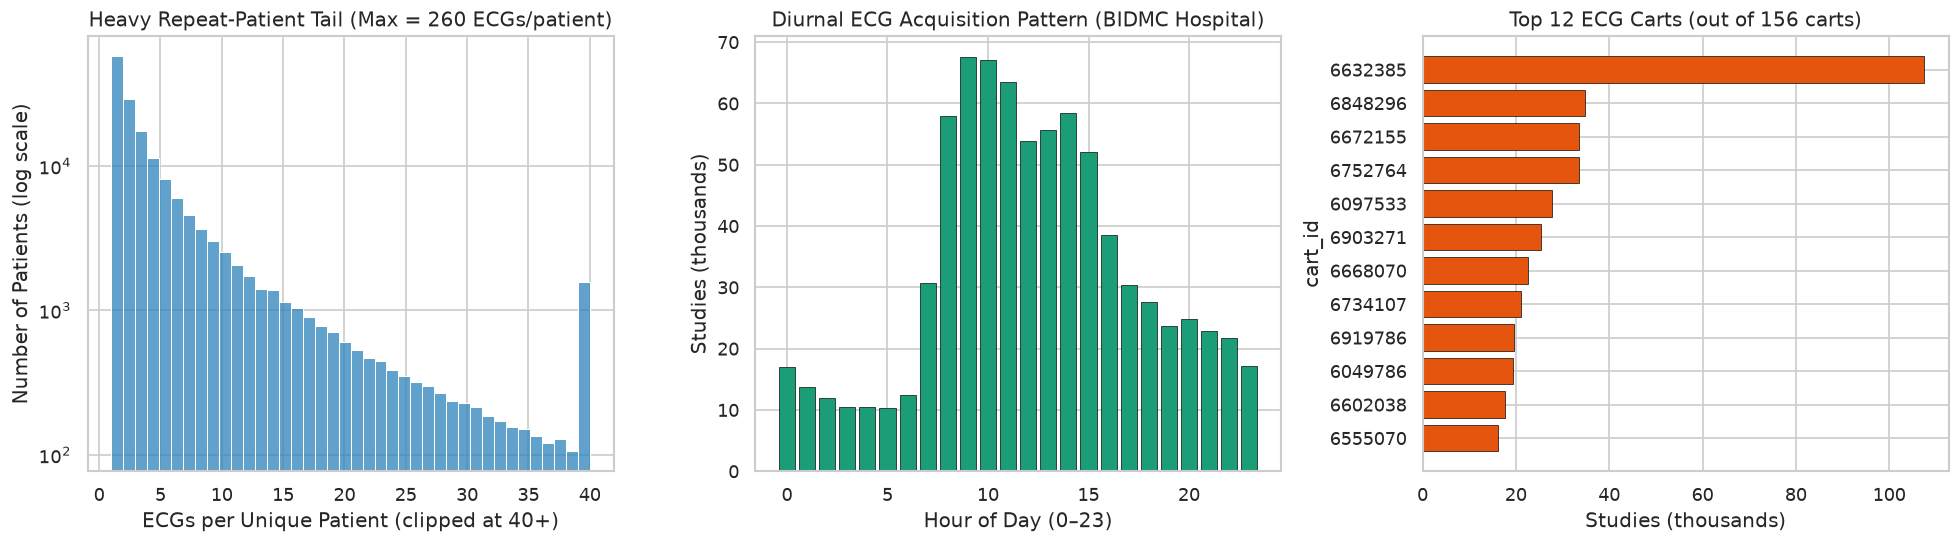

In [2]:
# Longitudinal studies-per-patient distribution, diurnal pattern & cart fleet
ecgs_per_subj = rl.groupby("subject_id").size()
print("ECGs per subject quantiles:", ecgs_per_subj.quantile([0.5, 0.75, 0.9, 0.95, 0.99, 1.0]).to_dict())
print(f"Patients with >= 2 ECGs : {(ecgs_per_subj >= 2).sum():,} ({(ecgs_per_subj >= 2).mean()*100:.1f}%), accounting for {ecgs_per_subj[ecgs_per_subj >= 2].sum():,} ({ecgs_per_subj[ecgs_per_subj >= 2].sum()/len(rl)*100:.1f}%) of all ECGs!")

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.7))

# Panel A: ECGs per patient (log-log / capped histogram)
sns.histplot(ecgs_per_subj.clip(upper=40), bins=40, color="#2b83ba", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_xlabel("ECGs per Unique Patient (clipped at 40+)")
axes[0].set_ylabel("Number of Patients (log scale)")
axes[0].set_title(f"Heavy Repeat-Patient Tail (Max = {ecgs_per_subj.max()} ECGs/patient)")

# Panel B: Hour-of-day capture pattern
hr_vc = rl["ecg_dt"].dt.hour.value_counts().sort_index()
axes[1].bar(hr_vc.index, hr_vc.values / 1000.0, color="#1b9e77", edgecolor="black", lw=0.4)
axes[1].set_xlabel("Hour of Day (0–23)")
axes[1].set_ylabel("Studies (thousands)")
axes[1].set_title("Diurnal ECG Acquisition Pattern (BIDMC Hospital)")

# Panel C: Top 12 ECG carts by volume
top_carts = mm_meta["cart_id"].value_counts().head(12)
axes[2].barh(top_carts.index.astype(str), top_carts.values / 1000.0, color="#e6550d", edgecolor="black", lw=0.4)
axes[2].invert_yaxis()
axes[2].set_xlabel("Studies (thousands)")
axes[2].set_ylabel("cart_id")
axes[2].set_title(f"Top 12 ECG Carts (out of {mm_meta['cart_id'].nunique()} carts)")

plt.tight_layout()
plt.show()